<a href="https://colab.research.google.com/github/oyrslufe/ESAA/blob/main/ESAA%201009%20assignment11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 2.4 파이토치 코드 맛보기

데이터셋 칼럼

price(자동차 가격), maint(자동차 유지 비용), doors(자동차 문 개수), persons(수용 인원), lug_capacity(수하물 용량), safety(안전성)

output(차 상태): 이 데이터는 unacc(허용 불가능한 수준), acc(허용 가능한 수준), 양호(good), 매우 좋은(very good, vgood) 중 하나의 값을 가짐

In [1]:
import torch
import torch .nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [2]:
cols = ['price', 'maint', 'doors', 'persons', 'lug_capacity', 'safety', 'output']
dataset = pd.read_csv('/content/car.data', names=cols)
display(dataset.head())

,price,maint,doors,persons,lug_capacity,safety,output
0,vhigh,vhigh,2,2,small,low,unacc
1,vhigh,vhigh,2,2,small,med,unacc
2,vhigh,vhigh,2,2,small,high,unacc
3,vhigh,vhigh,2,2,med,low,unacc
4,vhigh,vhigh,2,2,med,med,unacc


<Axes: ylabel='count'>

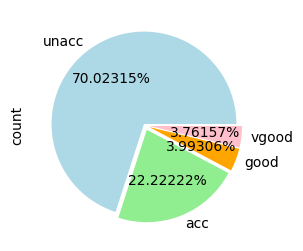

In [3]:
fig_size = plt.rcParams["figure.figsize"]
fig_size[0] = 8
fig_size[1] = 3
plt.rcParams["figure.figsize"] = fig_size
dataset.output.value_counts().plot(kind='pie' , autopct='%0.05f%%',
                                   colors=['lightblue', 'lightgreen', 'orange', 'pink' ], explode=(0.02, 0.05, 0.05, 0.05))

데이터 전처리

-> 데이터를 범주형 타입으로 변환

파이토치 이용하므로 범주형 타입을 텐서로 변환 필요.

범주형 데이터 -> dataset[category] -> 넘파이 배열 -> 텐서

- cat.codes: 범주형 데이터(단어)를 숫자(넘파이 배열)로 변환
- np.stack: 두 개 이상의 넘파이 객체 합칠 때 사용, 동일 차원의 배열을 새로운 축으로 합쳐 고차원으로 변경해줌
- np.concatenate: axis= 0, 1에 따라 선택한 축 기준으로 배열 연결

In [4]:
categorical_columns = ['price', 'maint', 'doors', 'persons','lug_capacity', 'safety']

for category in categorical_columns:
  dataset[category] = dataset[category].astype('category') # astype() 메서드를 이용하여 데이터를 범주형으로 변환

price = dataset['price'].cat.codes.values
maint = dataset['maint'].cat.codes.values
doors = dataset['doors'].cat.codes.values
persons = dataset['persons'].cat.codes.values
lug_capacity = dataset['lug_capacity'].cat.codes.values
safety = dataset['safety'].cat.codes.values

categorical_data = np.stack([price, maint, doors , persons, lug_capacity, safety], 1)
categorical_data[:10]

array([[3, 3, 0, 0, 2, 1],
       [3, 3, 0, 0, 2, 2],
       [3, 3, 0, 0, 2, 0],
       [3, 3, 0, 0, 1, 1],
       [3, 3, 0, 0, 1, 2],
       [3, 3, 0, 0, 1, 0],
       [3, 3, 0, 0, 0, 1],
       [3, 3, 0, 0, 0, 2],
       [3, 3, 0, 0, 0, 0],
       [3, 3, 0, 1, 2, 1]], dtype=int8)

In [5]:
categorical_data = torch.tensor(categorical_data, dtype=torch.int64)
categorical_data[:10]

tensor([[3, 3, 0, 0, 2, 1],
        [3, 3, 0, 0, 2, 2],
        [3, 3, 0, 0, 2, 0],
        [3, 3, 0, 0, 1, 1],
        [3, 3, 0, 0, 1, 2],
        [3, 3, 0, 0, 1, 0],
        [3, 3, 0, 0, 0, 1],
        [3, 3, 0, 0, 0, 2],
        [3, 3, 0, 0, 0, 0],
        [3, 3, 0, 1, 2, 1]])

레이블(outputs)로 사용할 칼럼을 텐서로 변환

- get_dummies: 문자를 가변수 숫자(0, 1) 즉, 넘파이 배열로 변환

텐서 차원 변환 함수

- ravel()
- reshape(-1)
- flatten()

2차원 텐서가 1차원으로 변경됨

In [6]:
outputs = pd.get_dummies(dataset.output)
outputs = outputs.values
outputs = torch. tensor(outputs).flatten()

print(categorical_data.shape)
print (outputs.shape)

torch.Size([1728, 6])
torch.Size([6912])


In [7]:
categorical_column_sizes = [len(dataset[column].cat.categories) for column in
                            categorical_columns]
categorical_embedding_sizes = [(col_size, min(50, (col_size+1)//2)) for col_size in
                               categorical_column_sizes]
print(categorical_embedding_sizes)

[(4, 2), (4, 2), (4, 2), (3, 2), (3, 2), (3, 2)]


In [8]:
total_records = 1728
test_records = int (total_records * .2)
categorical_train_data = categorical_data[:total_records - test_records]
categorical_test_data = categorical_data[total_records - test_records:total_records]
train_outputs = outputs[:total_records - test_records]
test_outputs = outputs[total_records - test_records:total_records]

In [9]:
print(len (categorical_train_data))
print(len(train_outputs))
print(len(categorical_test_data))
print(len(test_outputs))

1383
1383
345
345


In [10]:
class Model(nn.Module):
  def __init__(self, embedding_size, output_size, layers, p=0.4):
    super().__init__()
    self.all_embeddings = nn.ModuleList([nn.Embedding(ni, nf) for ni,
                                          nf in embedding_size])
    self.embedding_dropout = nn.Dropout(p)

    all_layers = []
    num_categorical_cols = sum((nf for ni, nf in embedding_size))
    input_size = num_categorical_cols

    for i in layers:
      all_layers.append (nn.Linear(input_size, i))
      all_layers.append(nn.ReLU(inplace=True ))
      all_layers.append (nn.BatchNorm1d(i))
      all_layers.append (nn.Dropout(p))
      input_size = i

    all_layers.append(nn.Linear(layers[-1], output_size))
    self.layers = nn. Sequential (*all_layers)

  def forward (self, x_categorical):
    embeddings = []
    for i,e in enumerate(self.all_embeddings):
      embeddings.append(e(x_categorical[:,i]))

    x = torch.cat(embeddings, 1)
    x = self.embedding_dropout(x)
    x = self.layers(x)
    return x

1. 클래스 형태로 구현되는 모델은 nn.Module을 상속받음
2. init()은 모델에서 사용될 파라미터와 신경망을 초기화하기 위한 용도로 사용, 객체가 생성될 때 자동으로 호출됨
3. super().init()은 부모 클래스(nn.Module)에 접근할 때 사용
4. 모델의 네트워크 계층으 구축하기 위해 for문을 이용해 각 계층을 all_layers 목록에 추가
5. forward() 함수는 학습 데이터를 입력받아서 연산 진행


In [11]:
model = Model(categorical_embedding_sizes, 4, [200, 100, 50] , p=0.4)
print(model)

Model(
  (all_embeddings): ModuleList(
    (0-2): 3 x Embedding(4, 2)
    (3-5): 3 x Embedding(3, 2)
  )
  (embedding_dropout): Dropout(p=0.4, inplace=False)
  (layers): Sequential(
    (0): Linear(in_features=12, out_features=200, bias=True)
    (1): ReLU(inplace=True)
    (2): BatchNorm1d(200, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (3): Dropout(p=0.4, inplace=False)
    (4): Linear(in_features=200, out_features=100, bias=True)
    (5): ReLU(inplace=True)
    (6): BatchNorm1d(100, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (7): Dropout(p=0.4, inplace=False)
    (8): Linear(in_features=100, out_features=50, bias=True)
    (9): ReLU(inplace=True)
    (10): BatchNorm1d(50, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (11): Dropout(p=0.4, inplace=False)
    (12): Linear(in_features=50, out_features=4, bias=True)
  )
)


In [12]:
loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters() , lr=0.001)

In [13]:
if torch.cuda.is_available():
  device = torch.device('cuda')
else:
  device = torch.device('cpu')

In [14]:
epochs = 500
aggregated_losses = []
train_outputs = train_outputs.to(device=device, dtype=torch.int64)

for i in range (epochs):
  i += 1
  y_pred = model(categorical_train_data).to(device)
  single_loss = loss_function(y_pred, train_outputs)
  aggregated_losses.append(single_loss)

  if i%25 == 1:
    print(f'epoch: {i:3} loss: {single_loss.item() :10.8f}')

  optimizer.zero_grad()
  single_loss.backward()
  optimizer.step()

print(f'epoch: {i:3} loss: {single_loss.item() :10.10f}')

epoch:   1 loss: 1.50818372
epoch:  26 loss: 1.31231081
epoch:  51 loss: 1.24223220
epoch:  76 loss: 1.14070272
epoch: 101 loss: 1.03795183
epoch: 126 loss: 0.91844761
epoch: 151 loss: 0.81496489
epoch: 176 loss: 0.73219079
epoch: 201 loss: 0.66880947
epoch: 226 loss: 0.66438651
epoch: 251 loss: 0.62049431
epoch: 276 loss: 0.61242700
epoch: 301 loss: 0.59345680
epoch: 326 loss: 0.60018182
epoch: 351 loss: 0.58646339
epoch: 376 loss: 0.59191889
epoch: 401 loss: 0.58174264
epoch: 426 loss: 0.57701349
epoch: 451 loss: 0.57340801
epoch: 476 loss: 0.56732714
epoch: 500 loss: 0.5666322708


In [15]:
test_outputs = test_outputs.to(device=device, dtype=torch.int64)
with torch.no_grad():
  y_val = model(categorical_test_data)
  loss = loss_function(y_val, test_outputs)
print(f'Loss: {loss:.8f}')

Loss: 0.56107783


In [16]:
print(y_val[:5])

tensor([[ 3.2300,  2.0520, -3.9377, -3.8590],
        [ 1.9243,  1.0398, -2.4303, -2.1242],
        [ 2.8921,  1.8383, -2.9272, -2.6340],
        [ 2.7388,  1.4336, -3.6788, -3.4288],
        [ 2.7643,  1.6437, -2.9875, -2.9330]])


In [17]:
y_val = np.argmax(y_val, axis=1)
print(y_val[:5])

tensor([0, 0, 0, 0, 0])


In [18]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
print(confusion_matrix(test_outputs,y_val))
print(classification_report(test_outputs, y_val))
print(accuracy_score(test_outputs, y_val))

[[259   0   0]
 [ 84   1   1]
 [  0   0   0]]
              precision    recall  f1-score   support

           0       0.76      1.00      0.86       259
           1       1.00      0.01      0.02        86
           2       0.00      0.00      0.00         0

    accuracy                           0.75       345
   macro avg       0.59      0.34      0.29       345
weighted avg       0.82      0.75      0.65       345

0.7536231884057971


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


**딥러닝 분류모델의 성능 평가 지표확인**

정확도 : TP + TN / 전체

재현율 : TP / TP + FN

정밀도 : TP / TP+FP

F1 score : 2* (정밀도*재현율) / (정밀도 + 재현율)